### Experiment 5 Re-creation

Below are the cells from `/content/Experiment_5.ipynb`. You can now run them in this notebook.

### Experiment Setup: Define Students

In [1]:
# ------------------------------------------------------------
# Step 1: Define Students
# ------------------------------------------------------------

students = [
    "Alice",
    "Bob",
    "Charlie",
    "David",
    "Eve",
    "Frank",
    "Grace",
    "Heidi",
    "Ivan",
    "Judy"
]

### Define Facts: Attendance and Performance

In [2]:
# ------------------------------------------------------------
# Step 2: Define Facts for New Predicates
# ------------------------------------------------------------

# New Predicates:
# CompletedCourses(x): True if student has completed required courses
completed_courses = [
    "Alice",
    "Charlie",
    "Eve",
    "Grace",
    "Ivan",
    "Judy"
]

# AttendanceAbove75(x): True if student attendance is above 75%
attendance_above_75 = [
    "Alice",
    "Charlie",
    "Eve",
    "Frank",
    "Grace",
    "Heidi",
    "Judy"
]

# HasBacklog(x): True if student has a backlog
has_backlog = [
    "Bob",
    "David",
    "Frank",
    "Heidi",
    "Ivan"
]

# GoodPerformance(x): True if student has good academic performance
good_performance = [
    "Alice",
    "Bob",
    "Eve",
    "Grace",
    "Judy"
]

### Define Rules for Academic Support

In [3]:
# ------------------------------------------------------------
# Step 3: Define New Inference Rules
# ------------------------------------------------------------

# Rule 1: EligibleForScholarship(x) based on assignment
eligible_for_scholarship = []
for student in students:
    if (student in attendance_above_75 and
        student in good_performance and
        student not in has_backlog):
        eligible_for_scholarship.append(student)

# Rule 2: NeedsAcademicSupport(x) - adapted from original
needs_academic_support = []
for student in students:
    if (student not in attendance_above_75 and student not in good_performance):
        if student not in needs_academic_support: # Avoid duplicates
            needs_academic_support.append(student)
    elif (student in good_performance and student in has_backlog):
        if student not in needs_academic_support: # Avoid duplicates
            needs_academic_support.append(student)
    elif (student in attendance_above_75 and student not in good_performance):
        if student not in needs_academic_support: # Avoid duplicates
            needs_academic_support.append(student)

# Rule 3: EligibleForProgression(x)
eligible_for_progression = []
for student in students:
    if (student in attendance_above_75 and
        student in good_performance and
        student in completed_courses and
        student not in needs_academic_support): # Students needing support are not eligible for immediate progression
        eligible_for_progression.append(student)

# Rule 4: NotRecommendedForScholarship(x) if they have a backlog (complementary to scholarship rule)
not_recommended_for_scholarship = []
for student in students:
    if student in has_backlog and student not in not_recommended_for_scholarship:
        not_recommended_for_scholarship.append(student)

# Also define recommendations for academic support based on new predicates
academic_support_recommendations = {}
for student in needs_academic_support:
    reasons = []
    if student not in attendance_above_75:
        reasons.append("Attendance below 75%")
    if student not in good_performance:
        reasons.append("Poor performance")
    if student in has_backlog:
        reasons.append("Has backlog")
    academic_support_recommendations[student] = reasons

### Generate Recommendations

In [4]:
# ------------------------------------------------------------
# Step 4: Generate Recommendations (Displaying new academic support recommendations)
# ------------------------------------------------------------

print("\n=============================================")
print("ACADEMIC SUPPORT RECOMMENDATIONS")
print("=============================================")

if academic_support_recommendations:
    for student, reasons in academic_support_recommendations.items():
        print(f"Student: {student}, Recommended Action: Academic Support, Reasons: {', '.join(reasons)}")
else:
    print("No students currently need academic support based on the defined rules.")



ACADEMIC SUPPORT RECOMMENDATIONS
Student: Bob, Recommended Action: Academic Support, Reasons: Attendance below 75%, Has backlog
Student: Charlie, Recommended Action: Academic Support, Reasons: Poor performance
Student: David, Recommended Action: Academic Support, Reasons: Attendance below 75%, Poor performance, Has backlog
Student: Frank, Recommended Action: Academic Support, Reasons: Poor performance, Has backlog
Student: Heidi, Recommended Action: Academic Support, Reasons: Poor performance, Has backlog
Student: Ivan, Recommended Action: Academic Support, Reasons: Attendance below 75%, Poor performance, Has backlog


### Visualize Results (Optional)

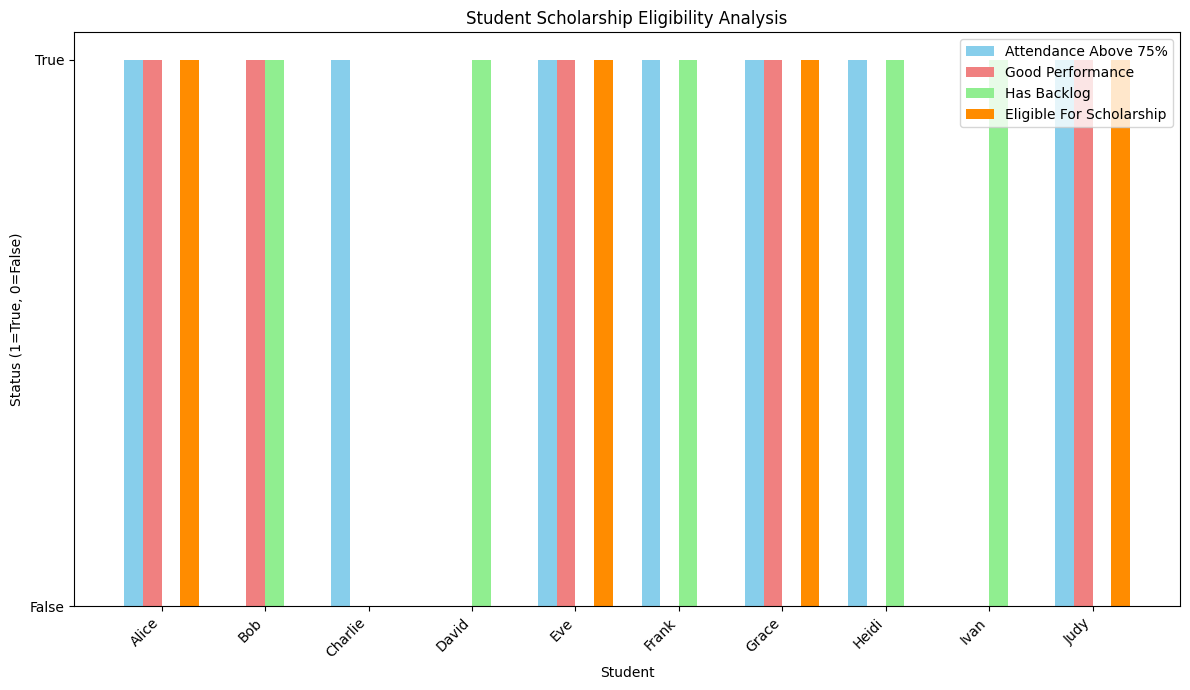

In [5]:
# ------------------------------------------------------------
# Step 5: Visualize Results (Scholarship Eligibility)
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import pandas as pd

# Prepare data for plotting scholarship eligibility
data_scholarship = {
    'Student': students,
    'AttendanceAbove75': [1 if s in attendance_above_75 else 0 for s in students],
    'GoodPerformance': [1 if s in good_performance else 0 for s in students],
    'HasBacklog': [1 if s in has_backlog else 0 for s in students],
    'EligibleForScholarship': [1 if s in eligible_for_scholarship else 0 for s in students]
}
df_scholarship = pd.DataFrame(data_scholarship)

fig, ax = plt.subplots(figsize=(12, 7))

bar_width = 0.18
index = range(len(students))

ax.bar(index, df_scholarship['AttendanceAbove75'], bar_width, label='Attendance Above 75%', color='skyblue')
ax.bar([i + bar_width for i in index], df_scholarship['GoodPerformance'], bar_width, label='Good Performance', color='lightcoral')
ax.bar([i + 2 * bar_width for i in index], df_scholarship['HasBacklog'], bar_width, label='Has Backlog', color='lightgreen')
ax.bar([i + 3 * bar_width for i in index], df_scholarship['EligibleForScholarship'], bar_width, label='Eligible For Scholarship', color='darkorange')

ax.set_xlabel('Student')
ax.set_ylabel('Status (1=True, 0=False)')
ax.set_title('Student Scholarship Eligibility Analysis')
ax.set_xticks([i + 1.5 * bar_width for i in index])
ax.set_xticklabels(students, rotation=45, ha='right')
ax.legend()
ax.set_yticks([0, 1])
ax.set_yticklabels(['False', 'True'])
plt.tight_layout()
plt.show()

### Query the Knowledge Base

In [6]:
# ------------------------------------------------------------
# Step 6: Query the Knowledge Base (Extended)
# ------------------------------------------------------------

print(" \n=============================================")
print("EXTENDED QUERY RESULTS")
print("=============================================")

def query_student_extended(student):
    print(" \nStudent:", student)
    print(f"  Completed Courses: {'YES' if student in completed_courses else 'NO'}")
    print(f"  Attendance Above 75%: {'YES' if student in attendance_above_75 else 'NO'}")
    print(f"  Has Backlog: {'YES' if student in has_backlog else 'NO'}")
    print(f"  Good Performance: {'YES' if student in good_performance else 'NO'}")

    if student in eligible_for_scholarship:
        print("  Eligible for Scholarship: YES")
    else:
        print("  Eligible for Scholarship: NO")

    if student in needs_academic_support:
        print(f"  Needs Academic Support: YES (Reasons: {', '.join(academic_support_recommendations.get(student, ['N/A']))})")
    else:
        print("  Needs Academic Support: NO")

    if student in eligible_for_progression:
        print("  Eligible for Progression: YES")
    else:
        print("  Eligible for Progression: NO")


# Query all students
for student in students:
    query_student_extended(student)

 
EXTENDED QUERY RESULTS
 
Student: Alice
  Completed Courses: YES
  Attendance Above 75%: YES
  Has Backlog: NO
  Good Performance: YES
  Eligible for Scholarship: YES
  Needs Academic Support: NO
  Eligible for Progression: YES
 
Student: Bob
  Completed Courses: NO
  Attendance Above 75%: NO
  Has Backlog: YES
  Good Performance: YES
  Eligible for Scholarship: NO
  Needs Academic Support: YES (Reasons: Attendance below 75%, Has backlog)
  Eligible for Progression: NO
 
Student: Charlie
  Completed Courses: YES
  Attendance Above 75%: YES
  Has Backlog: NO
  Good Performance: NO
  Eligible for Scholarship: NO
  Needs Academic Support: YES (Reasons: Poor performance)
  Eligible for Progression: NO
 
Student: David
  Completed Courses: NO
  Attendance Above 75%: NO
  Has Backlog: YES
  Good Performance: NO
  Eligible for Scholarship: NO
  Needs Academic Support: YES (Reasons: Attendance below 75%, Poor performance, Has backlog)
  Eligible for Progression: NO
 
Student: Eve
  Completed

### Explanation: Predicate Logic in Knowledge-Based DSS

Predicate Logic (also known as First-Order Logic) is a powerful formal system used for knowledge representation and reasoning in Artificial Intelligence, including Decision Support Systems (DSS). It extends propositional logic by allowing variables, predicates, and quantifiers, which enables it to represent more complex and general statements about the world.

Here's how Predicate Logic is applied in developing a knowledge-based DSS:

1.  **Knowledge Representation**: Predicate Logic allows for a precise and unambiguous representation of facts and rules that constitute the knowledge base of the DSS.
    *   **Predicates**: These are used to represent properties of objects or relationships between objects. For example, in our system, `CompletedCourses(x)`, `AttendanceAbove75(x)`, `HasBacklog(x)`, `GoodPerformance(x)`, and `EligibleForScholarship(x)` are predicates. They assert a property about a student `x`.
    *   **Constants**: Individual objects (e.g., "Alice", "Bob") are represented as constants.
    *   **Variables**: Represent general entities (e.g., `x` for any student).
    *   **Functions (Optional)**: Can be used to map objects to other objects, though not explicitly used in this simplified example.

2.  **Formalizing Facts**: Specific instances of predicates are facts. For example, `AttendanceAbove75(Alice)` is a fact indicating Alice's attendance is above 75%. In our Python implementation, these facts are represented as lists (e.g., `attendance_above_75 = ['Alice', 'Charlie', ...]`).

3.  **Defining Inference Rules**: These are logical implications (IF-THEN statements) that allow the system to derive new knowledge from existing facts. Rules are typically expressed using logical connectives (AND, OR, NOT) and implications (`=>`).
    *   **Example from our DSS**: The rule for scholarship eligibility can be expressed in predicate logic as:
        `AttendanceAbove75(x) AND GoodPerformance(x) AND NOT HasBacklog(x) => EligibleForScholarship(x)`
    *   In our Python code, this rule is implemented using `if` conditions and list comprehensions or loops that check for the presence/absence of a student in various fact lists.

4.  **Logical Inference**: The DSS uses an inference engine to apply these rules to the facts to deduce new conclusions. When a query is made (e.g., "Is Alice eligible for a scholarship?"), the system tries to prove the query by chaining together facts and rules.
    *   If `AttendanceAbove75(Alice)` is True, `GoodPerformance(Alice)` is True, and `HasBacklog(Alice)` is False, then by applying the `EligibleForScholarship` rule, the system infers that `EligibleForScholarship(Alice)` is True.

5.  **Advantages in DSS**: Predicate Logic provides several benefits for a DSS:
    *   **Expressiveness**: Can represent complex relationships and general principles.
    *   **Precision**: Eliminates ambiguity, making the system's reasoning clear and auditable.
    *   **Modularity**: Knowledge (facts and rules) can be added or modified independently.
    *   **Reasoning Capability**: Enables the system to make logical deductions and provide justifications for its recommendations.

In summary, Predicate Logic forms the backbone of a knowledge-based DSS by providing a structured and formal way to represent and reason with information, allowing the system to simulate human-like reasoning to support decision-making in specific domains, such as academic support and scholarship eligibility.

### Explanation: Predicate Logic in Knowledge-Based DSS

Predicate Logic (also known as First-Order Logic) is a powerful formal system used for knowledge representation and reasoning in Artificial Intelligence, including Decision Support Systems (DSS). It extends propositional logic by allowing variables, predicates, and quantifiers, which enables it to represent more complex and general statements about the world.

Here's how Predicate Logic is applied in developing a knowledge-based DSS:

1.  **Knowledge Representation**: Predicate Logic allows for a precise and unambiguous representation of facts and rules that constitute the knowledge base of the DSS.
    *   **Predicates**: These are used to represent properties of objects or relationships between objects. For example, in our system, `CompletedCourses(x)`, `AttendanceAbove75(x)`, `HasBacklog(x)`, `GoodPerformance(x)`, and `EligibleForScholarship(x)` are predicates. They assert a property about a student `x`.
    *   **Constants**: Individual objects (e.g., "Alice", "Bob") are represented as constants.
    *   **Variables**: Represent general entities (e.g., `x` for any student).
    *   **Functions (Optional)**: Can be used to map objects to other objects, though not explicitly used in this simplified example.

2.  **Formalizing Facts**: Specific instances of predicates are facts. For example, `AttendanceAbove75(Alice)` is a fact indicating Alice's attendance is above 75%. In our Python implementation, these facts are represented as lists (e.g., `attendance_above_75 = ['Alice', 'Charlie', ...]`).

3.  **Defining Inference Rules**: These are logical implications (IF-THEN statements) that allow the system to derive new knowledge from existing facts. Rules are typically expressed using logical connectives (AND, OR, NOT) and implications (`=>`).
    *   **Example from our DSS**: The rule for scholarship eligibility can be expressed in predicate logic as:
        `AttendanceAbove75(x) AND GoodPerformance(x) AND NOT HasBacklog(x) => EligibleForScholarship(x)`
    *   In our Python code, this rule is implemented using `if` conditions and list comprehensions or loops that check for the presence/absence of a student in various fact lists.

4.  **Logical Inference**: The DSS uses an inference engine to apply these rules to the facts to deduce new conclusions. When a query is made (e.g., "Is Alice eligible for a scholarship?"), the system tries to prove the query by chaining together facts and rules.
    *   If `AttendanceAbove75(Alice)` is True, `GoodPerformance(Alice)` is True, and `HasBacklog(Alice)` is False, then by applying the `EligibleForScholarship` rule, the system infers that `EligibleForScholarship(Alice)` is True.

5.  **Advantages in DSS**: Predicate Logic provides several benefits for a DSS:
    *   **Expressiveness**: Can represent complex relationships and general principles.
    *   **Precision**: Eliminates ambiguity, making the system's reasoning clear and auditable.
    *   **Modularity**: Knowledge (facts and rules) can be added or modified independently.
    *   **Reasoning Capability**: Enables the system to make logical deductions and provide justifications for its recommendations.

In summary, Predicate Logic forms the backbone of a knowledge-based DSS by providing a structured and formal way to represent and reason with information, allowing the system to simulate human-like reasoning to support decision-making in specific domains, such as academic support and scholarship eligibility.